## Pegasus Evaluation

The outline of the paper's evaluation. Every experiment states whether it can be run on

- **synthetic** data: generated service types and the queue simulator of `1_method_v2.ipynb`. A chain never repeats a
  service type: a seeded generator provides as many different service types as the chain is deep;
- **real** data: the testbed campaign in `statics/milos_results/` (experiment folders in brackets).

Limits of the real data that hold for every experiment:

- Per run and service, the campaign stores the mean, p50, p95 and p99 of the processing, waiting and total time, and
  for pipelines the same for the end-to-end time. Per-request traces exist only for pipelines; single-service runs
  have no per-item records.
- The copy is incomplete: many `traces.csv` and `trace_steps.csv` files and the `dataset.csv` of 01 and 03 are cut off
  in the middle of a line, 08a stopped early, and the last three experiments of the campaign are missing.
- The waiting time is several hundred milliseconds in every run, tens to hundreds of times the processing time, also at
  low load, and services run with several workers. The bounds model one FIFO server whose waiting comes from queueing
  only, so they cannot match the measured latency before that waiting is modeled.

In [1]:
# Data source of every experiment: "synthetic" (the simulated system of 1_method_v2.ipynb) or "real" (statics/milos_results)
data_source = "synthetic"

import warnings
from types import SimpleNamespace

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display
from sklearn.exceptions import ConvergenceWarning

from pegasus.data import load_chain_data, load_training_data, synthetic_chain
from pegasus.evaluation import (METHOD_COLORS, PROPOSED, PROPOSED_SNC, compare_methods, coverage, fit_services, holds, sweep_conclusion, sweep_line,
                                sweep_statistics, tightness_figure, tightness_sweep_figure, validity_legend)
from pegasus.bounds import martingale_closed_form_node_bound, network_service_bound, propagated_node_bounds, snc_latency_bound

alpha = 0.05                                           # violation probability epsilon: a bound at alpha bounds the (1 - alpha) latency quantile
confidence = 0.95                                      # the pessimistic mean of a bound lies above the true mean with this probability
coverage_check = dict(n_batches=10, confidence=0.95)   # confidence interval of a measured quantile (batch means)
seed = 35                                              # base seed of the data source
seeds = [0, 1, 2]                                      # every experiment is repeated for these seeds; a seed determines the generated service
                                                       # types, the training data and the held-out configurations
n_calibration = 20                                     # training configurations that Conformal sets aside for calibration; the rest trains its model
p_label = f"p{100 * (1 - alpha):g}"
pegasus_versions = [PROPOSED, PROPOSED_SNC]            # the two versions of the proposed method: union bound over node bounds, network service curve
competitors = [name for name in METHOD_COLORS if name != "Oracle"]   # the proposed method and the baselines; the Oracle is a reference
# B.2 to B.5 keep one of the two execution-time baselines. GP Sum stays, because it is the faster one: it uses the GPs that
# Pegasus and Kingman train anyway, while DNN Sum needs a network trained per service.
only_base_case = ("DNN Sum",)
sweep_methods = [name for name in METHOD_COLORS if name not in only_base_case]    # methods of B.2 to B.5, with the Oracle
sweep_competitors = [name for name in competitors if name not in only_base_case]  # the same without the Oracle

## A. Experimental Setup

### Service Generation

- **Synthetic:** yes. `synthetic_service` in `pegasus/data.py` generates every service type from the seed
  `service_seed`: an execution-time function and a noise level with randomly drawn parameters. A chain of depth K
  consists of the first K service types (`synthetic_chain`), so no service type occurs twice in a chain.
- **Real:** yes. Every service is measured alone (02a–h, 07a–f) and inside chains (04a–h, 06a–b), each service with
  its own configuration. Unseen configurations and unseen compositions are both possible: train on the single-service
  runs, test on the chains.

### Sampling Strategies

- **Synthetic:** uniform random yes; active learning and grid search possible, not implemented.
- **Real:** uniform random only, because the campaign drew its configurations at random. Active learning and grid
  search only as a selection among the measured runs.

### Baselines

Every baseline is trained on data of each service on its own, like the proposed method; none sees a run of the chain.

- **Synthetic:** yes. Execution-time model per service, summed, without queue (GP, DNN); queueing formula per service, summed; latency quantile per
  service with split budget, without and with a conformal step. All are in `pegasus/baselines.py`.
- **Real:** yes for the execution-time models and the queueing formula (processing times of 02a–h, 07a–f). The latency-quantile baselines need the
  latency quantile of every service alone under load: the single-service runs store p95 and p99, so only these two
  levels are available.

## B. Coverage and Tightness of Service Bounds

### B.1 Base Case

- **Synthetic:** yes (`1_method_v2.ipynb`, Sections 7g and 9).
- **Real:** yes. Chain qr → cv → face (04e), with the models of its services trained on 07a–c.
- **Baselines:** the three per-service categories of A (execution-time model summed, with GP and DNN; queueing formula per
  service; latency quantile per service with split budget, without and with a conformal step), and the union bound over measured nodes as reference.

**Setting.** The chain $s_1 \to s_2 \to s_3$ with every service at the same configuration, at held-out configurations
drawn from the training range; no held-out configuration occurs in the training data of any model. The ground truth
is the measured $(1-\varepsilon)$ quantile of the end-to-end latency of the chain, with $\varepsilon$ = `alpha`. The
experiment is repeated for every seed in `seeds`: a seed determines the three generated service types, the training
data and the held-out configurations. The figures pool the held-out configurations of all seeds; whether a method
holds is judged per seed (see Metrics).

**Independent services.** The execution times of an item at the different services of a chain are independent: the
simulator draws the execution-time noise of every service on its own (`item_correlation` = 0 in `pegasus/data.py`).
An item that is slow at one service is therefore not more likely to be slow at the next one. The latencies of an item
at consecutive services still depend on each other through the queues. This holds in every experiment of B.

**Training data.** Every method is trained on data of each service on its own and never on a run of the chain. The
proposed method, the two execution-time baselines and the queueing formula use one execution time per service and training configuration.
Quantile Union and Conformal use the latencies (waiting plus execution) of each service monitored alone under the
arrival process of the workload, at the same training configurations.

**Metrics.** *Tightness* of a method at a configuration is its end-to-end latency ÷ the measured quantile: 1 is exact,
above 1 is looser, below 1 is under the measured quantile. *Coverage* is the share of configurations at which a method
is not below the lower edge of the confidence interval of the measured quantile (`coverage_check`).

**Validity before tightness.** This rule is the same in every experiment of B.
- A method *reaches the confidence level* under a seed if its coverage over the held-out configurations of that seed
  is at least `confidence`.
- A method *holds* in a setting if it reaches the confidence level under every seed in `seeds`. A setting is the base
  case here, one number of training configurations in B.2 and one depth in B.3. The worst seed decides: a method with
  full coverage under all seeds but one that falls below `confidence` under the remaining seed does not hold, because
  a guarantee that depends on the drawn services and training data is not a guarantee.
- Every conclusion first names the methods that hold, and compares tightness only among those. The tightness of a
  method that does not hold describes a value that can lie below the measured quantile, not a bound.

**Methods.** The proposed method has two versions. Both use the same GP model of the execution time per service and
differ in how the services are composed; `explain_3_how_pegasus_bounds_compose.ipynb` derives both and tests their strengths
and weaknesses.
- *Pegasus per node (ours):* the union bound over martingale node bounds in closed form. The waiting time at a service is
  bounded by Kingman's martingale bound, an exponential tail whose rate follows from the moment generating function of
  the service's execution time and from its arrivals; with a Gaussian execution time, the latency bound of the service
  is then one formula. The first service receives the external arrivals, and every later service the departures of
  the service before it, which cannot be closer together than that service's execution times. Every service is bounded
  at the violation probability $\varepsilon / K$ for a chain of $K$ services, and the $K$ bounds are added; this is valid
  for any dependence between the services.
- *Pegasus SNC (ours):* one bound for the whole chain from its network service curve (stochastic network calculus, SNC).
  The latency moments of the services (the moment generating function of the execution time ÷ (1 − utilization at that
  parameter θ)) are multiplied, and one Chernoff step on the product bounds the end-to-end latency at the full
  violation probability $\varepsilon$. Multiplying the moments requires independent services (see Setting); no Hölder
  step is applied, which would cover dependent services at the price of a larger variance per service. Only the
  external arrivals enter this bound; the minimum spacing between the departures of a service, which the per-node
  version uses, is not exploited.
- *GP Sum, DNN Sum (baselines; execution-time model per service, summed, no queue):* the $(1-\varepsilon)$ quantile of the sum of the
  predicted execution times, with a GP and with a neural network (DNN) per service. Both are compared here; B.2 to B.6
  keep GP Sum only (`only_base_case`), the faster of the two, because the GPs are trained for Pegasus and Kingman anyway.
- *Kingman (baseline; queueing formula per service, summed):* the GP's mean and variance of the execution time enter a textbook
  formula for one queue (Kingman's approximation of the mean waiting time, an exponential waiting-time tail), which
  gives the $(1-\varepsilon)$ latency quantile of each service; the quantiles are added.
- *Quantile Union (baseline; latency quantile per service, split budget):* one GP per service predicts the
  $(1-\varepsilon/K)$ latency quantile of the service alone under load, for a chain of $K$ services; the predictions
  are added. This is the union bound applied to point predictions, trained on all training configurations.
  *Note:* the arrival rate is not an input of this model, so the model holds only for the workload its services were
  monitored under. With the arrival rate as an input (as in Fluxion), samples from existing executions at other loads
  could be reused for a new composition. The model would still not know that later services of a chain queue less:
  every service of a chain receives the same rate, and what changes is how evenly the arrivals are spaced.
- *Conformal (baseline; Quantile Union with a conformal step):* the same model, trained on the training
  configurations except `n_calibration` of them, on which a correction factor is calibrated (the ratio measured ÷
  predicted quantile). Every prediction is multiplied by that factor, so that it holds per service with probability
  `confidence`; the bounds of the services are added.
- *Oracle (reference):* the union bound over the measured latency quantiles of the services in the chain; it uses the ground
  truth and is not a competitor.

In [2]:
# Data of the chain and the per-service models for every seed, all trained on single-service data
bases, base_models = {}, {}
for s in seeds:
    bases[s] = load_chain_data(data_source, path=synthetic_chain(3), level=1 - alpha, coverage_check=coverage_check, seed=[seed, s], service_seed=s)
    assert not (bases[s].x_test[:, None, :] == bases[s].x_train[None, :, :]).all(axis=2).any(), "a held-out configuration occurs in the training data"
    base_models[s] = fit_services(bases[s], bases[s].x_train, bases[s].y_train, model_seed=seed + s, confidence=confidence)
base = bases[seeds[0]]   # for what is the same under every seed: the names in the chain, the workload, the numbers of configurations
K, workload = len(base.path), base.workload
print(f"{data_source} data, {len(seeds)} seeds: chain {' -> '.join(base.path)}, per seed {len(base.x_train)} training and {len(base.x_test)} held-out "
      f"configurations, {workload['process']} arrivals at {workload['rate']:g} items/s")

synthetic data, 3 seeds: chain s1 -> s2 -> s3, per seed 50 training and 100 held-out configurations, poisson arrivals at 4 items/s


In [3]:
def base_case(s):
    """Every method, and every composition of the ablation, for the chain of the seed s: two dictionaries
    name -> (group, end-to-end latency per held-out configuration in s)."""
    data, models = bases[s], base_models[s]
    methods, _ = compare_methods(data, models, data.x_train, data.monitored_latencies, alpha, confidence, n_calibration, model_seed=seed + s)
    beliefs, lower_means = models["beliefs"], models["lower_means"]
    # Ablation: the other ways to bound the nodes and to compose them, all on the same GP beliefs
    compositions = {
        "union bound, Chernoff (SNC) nodes": ("proposed", sum(snc_latency_bound(*b, epsilon=alpha / K, **workload) for b in beliefs)),
        "union bound, propagated Chernoff (SNC) nodes": ("proposed", propagated_node_bounds(beliefs, epsilon=alpha / K, path_lower_means=lower_means, **workload).sum(axis=0)),
        "union bound, martingale nodes": ("proposed", sum(martingale_closed_form_node_bound(*b, epsilon=alpha / K, **workload) for b in beliefs)),
        "union bound, propagated martingale nodes = Pegasus per node": ("proposed", methods[PROPOSED][1]),
        "network service curve, independent services = Pegasus SNC": ("proposed", methods[PROPOSED_SNC][1]),
        "network service curve, Hölder (any dependence)": ("proposed", network_service_bound(beliefs, epsilon=alpha, **workload)),
    }
    return methods, compositions


def pooled(results):
    """One dictionary name -> (group, latencies) from one per seed: the held-out configurations of all seeds, one seed after the other."""
    return {name: (results[0][name][0], np.concatenate([result[name][1] for result in results])) for name in results[0]}


def seeds_reached(results):
    """Number of seeds under which a method reaches the confidence level, name -> count, from one dictionary per seed."""
    return {name: sum(coverage(result[name][1], bases[s].measured_low) >= confidence for s, result in zip(seeds, results)) for name in results[0]}


per_seed = [base_case(s) for s in seeds]
methods, compositions = pooled([m for m, _ in per_seed]), pooled([c for _, c in per_seed])
methods_reached, compositions_reached = seeds_reached([m for m, _ in per_seed]), seeds_reached([c for _, c in per_seed])
# the ground truth of all seeds in the same order as the pooled latencies
base_pooled = SimpleNamespace(path=base.path, workload=workload, x_test=np.concatenate([bases[s].x_test for s in seeds]),
                              measured=np.concatenate([bases[s].measured for s in seeds]),
                              measured_low=np.concatenate([bases[s].measured_low for s in seeds]))
print(f"{len(methods)} methods and {len(compositions)} compositions computed for {len(seeds)} seeds.")

8 methods and 6 compositions computed for 3 seeds.


**Figures.** Both figures have one row per method and show its tightness over the held-out configurations on a
logarithmic axis (box: quartiles, line: median, whiskers and points: the remaining configurations; configurations
without a finite latency are left out). The vertical line at 1× is the measured quantile: a value to the left of
that line is below the measured quantile. The column "seeds" right of the rows gives the number of seeds under which
the method reaches the confidence level. A filled box is a method that holds, i.e. reaches the level under every seed;
a hatched box is a method that does not hold. Look at the hatching first and compare the position of the boxes only
among the filled ones. The first figure compares the two versions of the proposed method with the
baselines. The second is an ablation: every way to bound the nodes and to compose them on the same GP models. Its rows
name the two versions of Pegasus. The first four rows add one bound per service (union bound); the last two bound the
whole chain with its network service curve, without and with the Hölder step. With the Hölder step the bound also
holds for dependent services, which do not occur here, so the difference between the last two rows is what that
step costs.

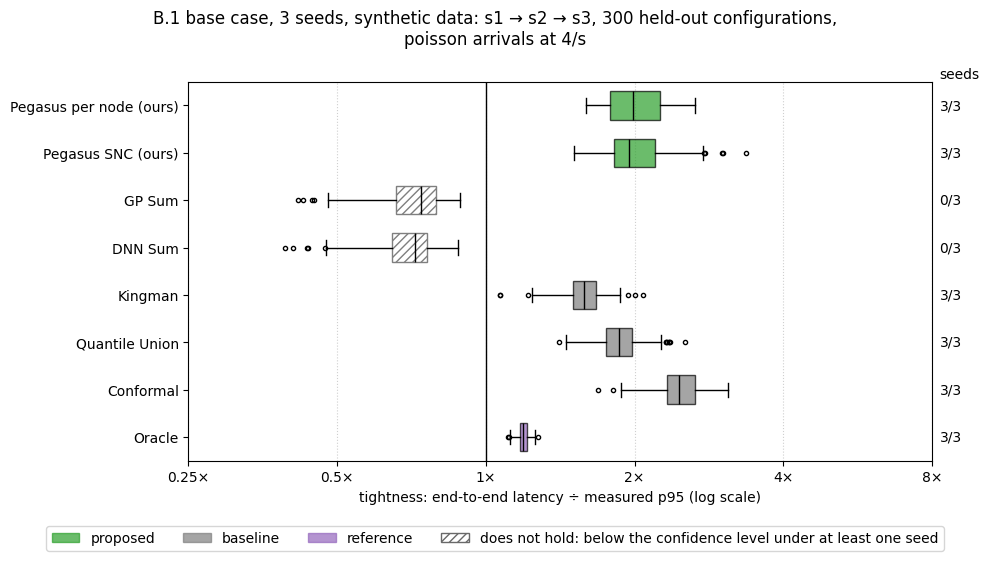

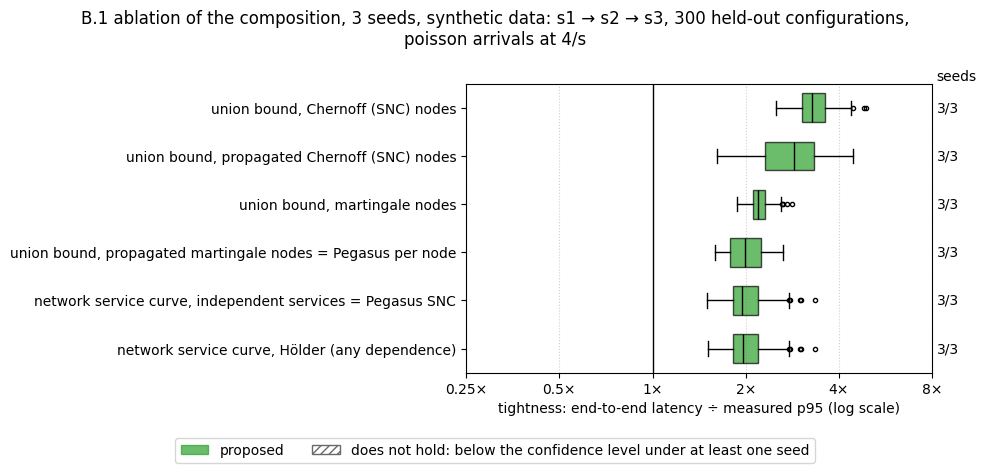

In [4]:
tightness_figure(methods, base_pooled, f"B.1 base case, {len(seeds)} seeds, {data_source} data", p_label, methods_reached, len(seeds))
tightness_figure(compositions, base_pooled, f"B.1 ablation of the composition, {len(seeds)} seeds, {data_source} data", p_label, compositions_reached, len(seeds))

In [5]:
base_tightness = lambda name: np.median(methods[name][1] / base_pooled.measured)   # median over the held-out configurations of all seeds
base_holding = [name for name in competitors if methods_reached[name] == len(seeds)]
base_failing = [name for name in competitors if methods_reached[name] < len(seeds)]
guaranteed = [name for name, (group, _) in compositions.items() if group == "proposed"]
display(Markdown(
    f"**What this shows** ({data_source} data, {workload['process']} arrivals at {workload['rate']:g} items/s, ε = {alpha:g}, {len(seeds)} seeds).\n"
    f"- **Validity.** Methods that hold, i.e. reach the confidence level under every seed: {', '.join(base_holding) or 'none'}. "
    f"Methods that do not hold: "
    + (", ".join(f"{name} (reaches it under {methods_reached[name]} of {len(seeds)} seeds)" for name in base_failing) or "none")
    + ".\n"
    f"- **Tightness among the methods that hold** (median over the held-out configurations of all seeds): "
    + (", ".join(f"{name} {base_tightness(name):.2f}×" for name in sorted(base_holding, key=base_tightness)) or "no method holds")
    + ".\n"
    f"- **Ablation.** {sum(compositions_reached[name] == len(seeds) for name in guaranteed)} of the {len(guaranteed)} compositions with a guarantee hold."
))

**What this shows** (synthetic data, poisson arrivals at 4 items/s, ε = 0.05, 3 seeds).
- **Validity.** Methods that hold, i.e. reach the confidence level under every seed: Pegasus per node (ours), Pegasus SNC (ours), Kingman, Quantile Union, Conformal. Methods that do not hold: GP Sum (reaches it under 0 of 3 seeds), DNN Sum (reaches it under 0 of 3 seeds).
- **Tightness among the methods that hold** (median over the held-out configurations of all seeds): Kingman 1.58×, Quantile Union 1.86×, Pegasus SNC (ours) 1.94×, Pegasus per node (ours) 1.99×, Conformal 2.46×.
- **Ablation.** 6 of the 6 compositions with a guarantee hold.

### B.2 Varying Evidence per Service

- **Synthetic:** yes, by varying `n_train`. The simulator cannot test the transfer between compositions, because a
  service's execution time does not depend on the chain there.
- **Real:** yes. Subsample the single-service runs (02a–h, 07a–f). The same services are also measured inside other
  compositions (trees 01 and 03, other chains), which gives training data from a composition different from the target.
- **Baselines:** as in B.1 without DNN Sum (see Methods in B.1), each with the same number of single-service runs as
  the proposed method.


**Setting.** For every seed, the chain, the held-out configurations and the ground truth of B.1. Only the
single-service training data changes: `evidence_sizes` training configurations per service, drawn anew for every size
and seed. No held-out configuration occurs in any of them. Conformal sets aside the same share of its configurations
for calibration as in B.1, and at least 19, the fewest that give it a finite bound; it is left out where fewer than 5
configurations would remain to train its model. The Oracle uses no training data.

**Complexity (analyzed here, against the amount of training data).** The *computing time* of a method is the time to
train the models it uses and to compute its end-to-end latency at the held-out configurations, in seconds on the
machine that ran the notebook. It does not contain the time to collect the training data: one execution time per
service and configuration for both versions of Pegasus, GP Sum and Kingman, a run under load per service and
configuration for Quantile Union and Conformal. The complexity against the depth of the chain is analyzed in B.3.

**Figure.** The horizontal axis is the number of training configurations per service (logarithmic). *Left:* tightness,
for every seed the median over its held-out configurations; the horizontal line at 1× is the measured quantile, and a
value under that line is below the measured quantile. *Right:* computing time (s, logarithmic). Every line is the
median over the seeds, and the band around it reaches from the smallest to the largest seed. In the left panel a
filled marker means that the method holds at that number of training configurations (it reaches the confidence level
under every seed, as defined in B.1), and a hollow marker that it does not. Look at the markers first: only lines with
filled markers are bounds whose tightness can be compared.

In [6]:
# B.2: the chains of B.1 with single-service training data of different sizes
evidence_sizes = [10, 15, 25, 50, 100, 200]             # training configurations per service
calibration_share = n_calibration / len(base.x_train)   # share that Conformal sets aside for calibration, as in B.1
evidence, evidence_seconds = {}, {}                     # (size, seed) -> name -> (group, latency per held-out configuration) / computing time in s
with warnings.catch_warnings():
    # with few training configurations the fitted GP hyperparameters often end at their bounds, and scikit-learn warns for every model
    warnings.simplefilter("ignore", ConvergenceWarning)
    for size in evidence_sizes:
        for s in seeds:
            x_train, y_train, monitored = load_training_data(data_source, services=bases[s].path, workload=workload, n_train=size,
                                                             seed=[seed, s, size], service_seed=s)
            assert not (bases[s].x_test[:, None, :] == x_train[None, :, :]).all(axis=2).any(), "a held-out configuration occurs in the training data"
            models = fit_services(bases[s], x_train, y_train, model_seed=seed + s, confidence=confidence, with_dnn=False)
            evidence[(size, s)], evidence_seconds[(size, s)] = compare_methods(
                bases[s], models, x_train, monitored, alpha, confidence, n_calibration=max(19, round(calibration_share * size)), model_seed=seed + s,
                leave_out=only_base_case)
print(f"{len(evidence)} training sets evaluated.")

18 training sets evaluated.


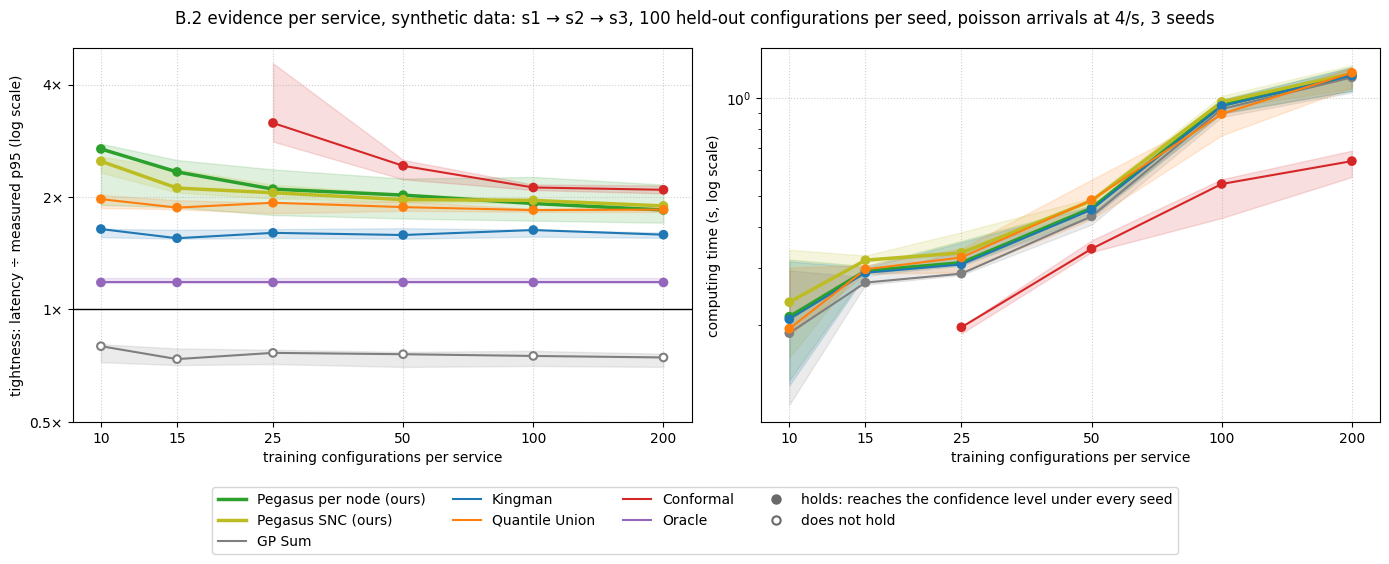

In [7]:
def over_evidence(name, statistic):
    """statistic(latency, data of the seed) of a method for every size and seed, (sizes, seeds); nan where the method was left out."""
    return np.array([[statistic(evidence[(size, s)][name][1], bases[s]) if name in evidence[(size, s)] else np.nan for s in seeds]
                     for size in evidence_sizes])


evidence_coverage = {name: over_evidence(name, lambda latency, data: coverage(latency, data.measured_low)) for name in sweep_methods}
evidence_tightness = {name: over_evidence(name, lambda latency, data: np.median(latency / data.measured)) for name in sweep_methods}
evidence_time = {name: np.array([[sum(evidence_seconds[(size, s)].get(name, (np.nan, np.nan))) for s in seeds] for size in evidence_sizes])
                 for name in sweep_competitors}
evidence_holds = {name: holds(evidence_coverage[name], confidence) for name in sweep_methods}   # per size: reaches the confidence level under every seed

fig, (ax_tight, ax_time) = plt.subplots(1, 2, figsize=(14, 4.8))
for name in sweep_methods:
    sweep_line(ax_tight, evidence_sizes, evidence_tightness[name], name, held=evidence_holds[name])
    if name in evidence_time:
        sweep_line(ax_time, evidence_sizes, evidence_time[name], name)
for ax in (ax_tight, ax_time):
    ax.set_xscale("log")
    ax.set_xticks(evidence_sizes, [str(size) for size in evidence_sizes])
    ax.minorticks_off()
    ax.set_xlabel("training configurations per service")
    ax.grid(True, linestyle=":", alpha=0.6)
ax_tight.axhline(1.0, color="black", linewidth=1)
ax_tight.set_yscale("log")
ax_tight.set_yticks([0.5, 1, 2, 4], ["0.5×", "1×", "2×", "4×"])
ax_tight.minorticks_off()
ax_tight.set_ylabel(f"tightness: latency ÷ measured {p_label} (log scale)")
ax_time.set_yscale("log")
ax_time.set_ylabel("computing time (s, log scale)")
handles, labels = ax_tight.get_legend_handles_labels()
marker_handles, marker_labels = validity_legend()
fig.legend(handles + marker_handles, labels + marker_labels, loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=4)
fig.suptitle(f"B.2 evidence per service, {data_source} data: {' → '.join(base.path)}, {len(base.x_test)} held-out configurations per seed, "
             f"{workload['process']} arrivals at {workload['rate']:g}/s, {len(seeds)} seeds")
plt.tight_layout()
plt.show()

In [8]:
evidence_computed = {name: ~np.isnan(evidence_coverage[name]).all(axis=1) for name in sweep_competitors}   # per size: the method was not left out
typical = lambda values, name: np.nanmedian(values[name][evidence_computed[name]], axis=1)                   # per size with a value, median over the seeds
sizes_of = lambda name: np.array(evidence_sizes)[evidence_computed[name]]
evidence_holding = [name for name in sweep_competitors if evidence_holds[name][evidence_computed[name]].all()]
evidence_failing = {name: [size for size, held in zip(sizes_of(name), evidence_holds[name][evidence_computed[name]]) if not held]
                    for name in sweep_competitors if name not in evidence_holding}
display(Markdown(
    f"**What this shows** ({data_source} data, {workload['process']} arrivals at {workload['rate']:g} items/s, ε = {alpha:g}, {len(seeds)} seeds).\n"
    f"- **Validity.** Methods that hold at every number of training configurations at which they are computed, i.e. reach the confidence level "
    f"under every seed: {', '.join(evidence_holding) or 'none'}. Methods that do not hold, and at which sizes: "
    + ("; ".join(f"{name} at {'every size' if len(sizes) == len(sizes_of(name)) else ', '.join(map(str, sizes))}" for name, sizes in evidence_failing.items())
       or "none")
    + ".\n"
    f"- **Tightness among the methods that hold** (median over the seeds): "
    + ("; ".join(f"{name} from {typical(evidence_tightness, name)[0]:.2f}× with {sizes_of(name)[0]} training configurations to "
                 f"{typical(evidence_tightness, name)[-1]:.2f}× with {sizes_of(name)[-1]}" for name in evidence_holding) or "no method holds")
    + ".\n"
    f"- **Computing time** with {evidence_sizes[-1]} training configurations: "
    + ", ".join(f"{name} {seconds:.2g} s" for name, seconds in sorted(((name, typical(evidence_time, name)[-1]) for name in evidence_time), key=lambda item: -item[1]))
    + f". With {evidence_sizes[0]} training configurations: "
    + ", ".join(f"{name} {typical(evidence_time, name)[0]:.2g} s" for name in pegasus_versions) + "."
))

**What this shows** (synthetic data, poisson arrivals at 4 items/s, ε = 0.05, 3 seeds).
- **Validity.** Methods that hold at every number of training configurations at which they are computed, i.e. reach the confidence level under every seed: Pegasus per node (ours), Pegasus SNC (ours), Kingman, Quantile Union, Conformal. Methods that do not hold, and at which sizes: GP Sum at every size.
- **Tightness among the methods that hold** (median over the seeds): Pegasus per node (ours) from 2.69× with 10 training configurations to 1.85× with 200; Pegasus SNC (ours) from 2.49× with 10 training configurations to 1.89× with 200; Kingman from 1.64× with 10 training configurations to 1.59× with 200; Quantile Union from 1.97× with 10 training configurations to 1.85× with 200; Conformal from 3.16× with 25 training configurations to 2.09× with 200.
- **Computing time** with 200 training configurations: Quantile Union 1.2 s, Pegasus SNC (ours) 1.2 s, Kingman 1.2 s, Pegasus per node (ours) 1.2 s, GP Sum 1.2 s, Conformal 0.64 s. With 10 training configurations: Pegasus per node (ours) 0.21 s, Pegasus SNC (ours) 0.24 s.

### B.3 Varying Chain Depth

- **Synthetic:** yes.
- **Real:** partly. Depth 1 (02a–h, 07a–f), 2 (04a–d), 3 (04e–f), 4 (04g), 5 (04h) and 10 (06a–b). Nothing at 20
  or 50.
- **Baselines:** as in B.1 without DNN Sum. The conformal bound splits its budget over the services, like the union bound.

**Setting.** Chains of depth $K$ (`depths`) of $K$ different service types, $s_1 \to s_2 \to \dots \to s_K$
(`synthetic_chain`): the chain of depth 3 is the chain of B.1, and every deeper chain adds further service types.
Every position has its own queue, and all positions run at the same configuration. The training configurations and
the held-out configurations are those of B.1 at every depth, every service has its own training data, and the ground
truth is simulated anew for every depth. All of this is repeated for every seed in `seeds`. Metrics and methods are those of B.1.

Two things change with the depth for every method that splits the violation budget (Pegasus per node, Quantile Union,
Conformal, Oracle): each service is bounded at the level $1 - \varepsilon / K$, which moves further into the tail as $K$
grows. The runs that Quantile Union, Conformal and the Oracle read that quantile from have a fixed number of items, so
for the deepest chains only a handful of items lie beyond it and their values rest on very few observations.
Pegasus SNC does not split the budget: it bounds the whole chain at $\varepsilon$, with one parameter θ shared by all
services.

**Complexity (analyzed here, against the depth).** A node bound of Pegasus per node is one formula and a short search
on it, so its computing time does not depend on the budget ε / K of a service. Every position of a chain gets its own
node bound: the computing time of Pegasus per node is expected to grow linearly with K. Pegasus SNC adds one latency
moment per position, on a grid of values of θ, and minimizes once over that grid, so its computing time is expected to
grow linearly with K as well. The *computing time* here is the time to compute a method's end-to-end latency
at the held-out configurations. It does not contain the training of the execution-time models, of which there is one
per service, so that their training time grows linearly with the depth as well; Quantile Union and Conformal train
their own model per service and depth, which is part of their time.

**Figure.** The horizontal axis is the depth $K$ (logarithmic). *Left:* tightness, for every seed the median over its
held-out configurations. The horizontal line at 1× is the measured quantile: a value under that line is below the
measured quantile. *Right:* computing time (s, logarithmic). Every line is the median over the seeds, and the band
around it reaches from the smallest to the largest seed. In the left panel a filled marker means that the method holds
at that depth (it reaches the confidence level under every seed, as defined in B.1), and a hollow marker that it does
not. Look at the markers first: only lines with filled markers are bounds whose tightness can be compared.

In [9]:
# B.3: chains of different depth, every position a different service type, at the held-out configurations of B.1
depths = [1, 2, 5, 10, 20, 50]
depth_truth, depth_methods, depth_seconds = {}, {}, {}   # (seed, depth) -> ...
with warnings.catch_warnings():
    # for some services the fitted GP hyperparameters end at their bounds, and scikit-learn warns for every such model
    warnings.simplefilter("ignore", ConvergenceWarning)
    for s in seeds:
        for depth in depths:
            data = load_chain_data(data_source, path=synthetic_chain(depth), level=1 - alpha, coverage_check=coverage_check, seed=[seed, s], service_seed=s)
            assert np.array_equal(data.x_test, bases[s].x_test), "the held-out configurations differ from those of B.1"
            assert not (data.x_test[:, None, :] == data.x_train[None, :, :]).all(axis=2).any(), "a held-out configuration occurs in the training data"
            models = fit_services(data, data.x_train, data.y_train, model_seed=seed + s, confidence=confidence, with_dnn=False)
            depth_methods[(s, depth)], depth_seconds[(s, depth)] = compare_methods(data, models, data.x_train, data.monitored_latencies, alpha, confidence,
                                                                                   n_calibration, model_seed=seed + s, leave_out=only_base_case)
            depth_truth[(s, depth)] = (data.measured, data.measured_low)   # the traces of a deep chain are large, so only the measured quantile is kept
            if s == seeds[0] and depth == depths[-1]:   # one deepest chain, for the figure of the minimum spacing
                deepest_path, deepest_models, deepest_x_test = data.path, models, data.x_test
        print(f"seed {s}: depths up to {depths[-1]} evaluated")

seed 0: depths up to 50 evaluated


seed 1: depths up to 50 evaluated


seed 2: depths up to 50 evaluated


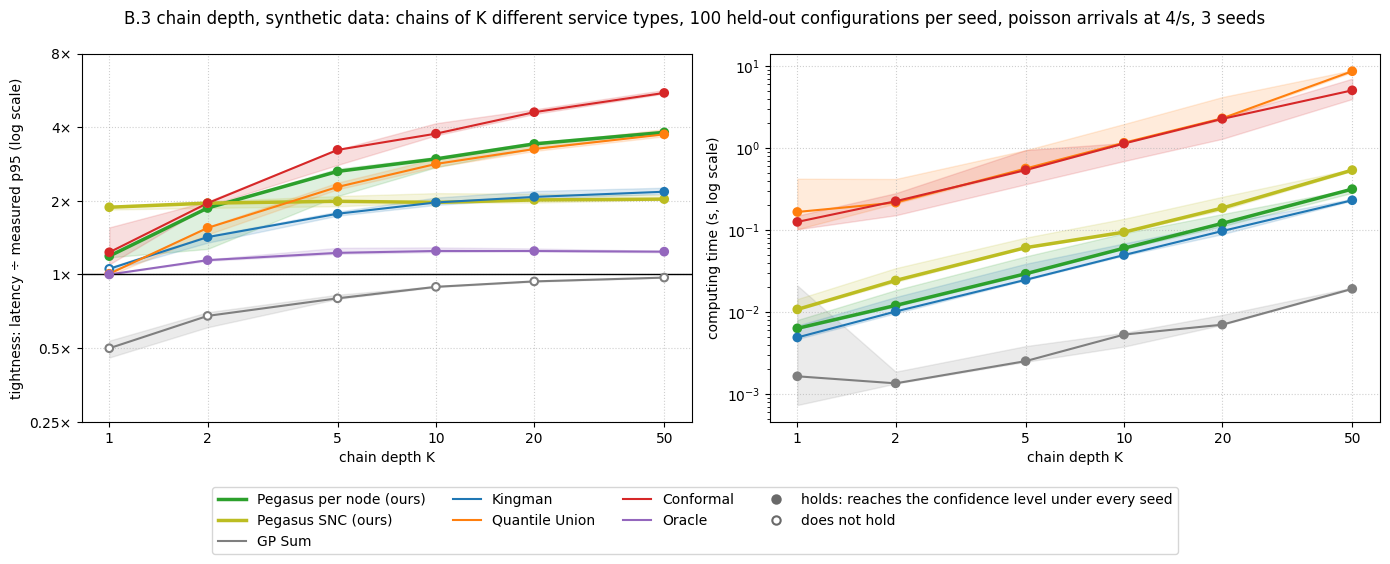

In [10]:
def over_depths(name, statistic):
    """statistic(latency, measured, measured_low) of a method for every depth and seed, (depths, seeds); infinite values become nan."""
    values = np.array([[statistic(depth_methods[(s, depth)][name][1], *depth_truth[(s, depth)]) for s in seeds] for depth in depths], dtype=float)
    return np.where(np.isfinite(values), values, np.nan)


depth_coverage = {name: over_depths(name, lambda latency, measured, low: coverage(latency, low)) for name in sweep_methods}
depth_tightness = {name: over_depths(name, lambda latency, measured, low: np.median(latency / measured)) for name in sweep_methods}
depth_time = {name: np.array([[depth_seconds[(s, depth)][name][1] for s in seeds] for depth in depths]) for name in depth_seconds[(seeds[0], depths[0])]}
depth_holds = {name: holds(depth_coverage[name], confidence) for name in sweep_methods}   # per depth: reaches the confidence level under every seed

fig, (ax_tight, ax_time) = plt.subplots(1, 2, figsize=(14, 4.8))
for name in sweep_methods:
    sweep_line(ax_tight, depths, depth_tightness[name], name, held=depth_holds[name])
    if name in depth_time:
        sweep_line(ax_time, depths, depth_time[name], name)
for ax in (ax_tight, ax_time):
    ax.set_xscale("log")
    ax.set_xticks(depths, [str(depth) for depth in depths])
    ax.minorticks_off()
    ax.set_xlabel("chain depth K")
    ax.grid(True, linestyle=":", alpha=0.6)
ax_tight.axhline(1.0, color="black", linewidth=1)
ax_tight.set_yscale("log")
ax_tight.set_yticks([0.25, 0.5, 1, 2, 4, 8], ["0.25×", "0.5×", "1×", "2×", "4×", "8×"])
ax_tight.minorticks_off()
ax_tight.set_ylabel(f"tightness: latency ÷ measured {p_label} (log scale)")
ax_time.set_yscale("log")
ax_time.set_ylabel("computing time (s, log scale)")
handles, labels = ax_tight.get_legend_handles_labels()
marker_handles, marker_labels = validity_legend()
fig.legend(handles + marker_handles, labels + marker_labels, loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=4)
fig.suptitle(f"B.3 chain depth, {data_source} data: chains of K different service types, {len(base.x_test)} held-out configurations per seed, "
             f"{workload['process']} arrivals at {workload['rate']:g}/s, {len(seeds)} seeds")
plt.tight_layout()
plt.show()

In [11]:
depth_median = {name: np.nanmedian(depth_tightness[name], axis=1) for name in sweep_methods}   # per depth, median over the seeds
depth_holding = [name for name in sweep_competitors if depth_holds[name].all()]
below = {name: {depth: int(np.sum(depth_coverage[name][k] < confidence)) for k, depth in enumerate(depths)}   # per depth, number of seeds below the level
         for name in sweep_competitors if name not in depth_holding}
computing = {name: np.median(times, axis=1) for name, times in depth_time.items()}                 # per depth, median over the seeds
growth = lambda seconds: np.log(seconds[-1] / seconds[-2]) / np.log(depths[-1] / depths[-2])   # exponent of K between the two deepest chains
slowest_baseline = max((name for name in computing if name not in pegasus_versions), key=lambda name: computing[name][-1])


def where_below(counts):
    if all(count == len(seeds) for count in counts.values()):
        return "at every depth under every seed"
    return ", ".join(f"at depth {depth} under {count} of {len(seeds)} seeds" for depth, count in counts.items() if count)


display(Markdown(
    f"**What this shows** ({data_source} data, {workload['process']} arrivals at {workload['rate']:g} items/s, ε = {alpha:g}, {len(seeds)} seeds).\n"
    f"- **Validity.** Methods that hold at every depth, i.e. reach the confidence level under every seed: {', '.join(depth_holding) or 'none'}. "
    f"Methods that do not hold, and where they are below the confidence level: "
    + ("; ".join(f"{name} {where_below(counts)}" for name, counts in below.items()) or "none")
    + ".\n"
    f"- **Tightness among the methods that hold** (median over the seeds): "
    + ("; ".join(f"{name} {depth_median[name][0]:.2f}× at depth {depths[0]} and {depth_median[name][-1]:.2f}× at depth {depths[-1]}" for name in depth_holding)
       or "no method holds")
    + f". The Oracle, the union bound over measured services, is at {depth_median['Oracle'][0]:.2f}× and {depth_median['Oracle'][-1]:.2f}×.\n"
    f"- **Computing time** at depth {depths[-1]}, median over the seeds: "
    + ", ".join(f"{name} {computing[name][-1]:.3g} s" for name in pegasus_versions)
    + f", the slowest baseline ({slowest_baseline}) {computing[slowest_baseline][-1]:.2g} s. Between the two deepest chains the time grows with K to the power "
    + " and ".join(f"{growth(computing[name]):.1f} ({name})" for name in pegasus_versions) + "."
))

**What this shows** (synthetic data, poisson arrivals at 4 items/s, ε = 0.05, 3 seeds).
- **Validity.** Methods that hold at every depth, i.e. reach the confidence level under every seed: Pegasus per node (ours), Pegasus SNC (ours), Conformal. Methods that do not hold, and where they are below the confidence level: GP Sum at every depth under every seed; Kingman at depth 1 under 2 of 3 seeds; Quantile Union at depth 1 under 3 of 3 seeds.
- **Tightness among the methods that hold** (median over the seeds): Pegasus per node (ours) 1.19× at depth 1 and 3.81× at depth 50; Pegasus SNC (ours) 1.88× at depth 1 and 2.03× at depth 50; Conformal 1.23× at depth 1 and 5.52× at depth 50. The Oracle, the union bound over measured services, is at 1.00× and 1.24×.
- **Computing time** at depth 50, median over the seeds: Pegasus per node (ours) 0.316 s, Pegasus SNC (ours) 0.539 s, the slowest baseline (Quantile Union) 8.7 s. Between the two deepest chains the time grows with K to the power 1.1 (Pegasus per node (ours)) and 1.2 (Pegasus SNC (ours)).

**Figure (minimum spacing).** This figure concerns Pegasus per node only; Pegasus SNC does not use the spacing between
the departures of a service. The figure below shows the deepest chain of the first seed position by position: the
processing time of every service (the mean execution time that its GP predicts, in ms) and the *minimum spacing* of its
arrivals. The minimum spacing is the smallest gap that two consecutive items can have when they arrive at the service.
It equals the processing time of the service before, because that service handles one item at a time and so cannot
release two items closer together than it needs for one. The actual gaps are usually larger. Lines are the median over
the held-out configurations, bands the first to third quartile. Where the minimum spacing lies below the processing
time, the service sits behind a faster one: items can arrive faster than it processes them for a while, and it can
queue; these positions are circled. The conclusion below the figure gives two shares over all later positions and
held-out configurations: how often the service before is faster, and how often Pegasus per node cannot use the minimum
spacing, which is more often, because Pegasus per node requires the optimistic mean of the service before to exceed the
pessimistic mean of the service itself. In those cases Pegasus per node falls back on the external arrivals.

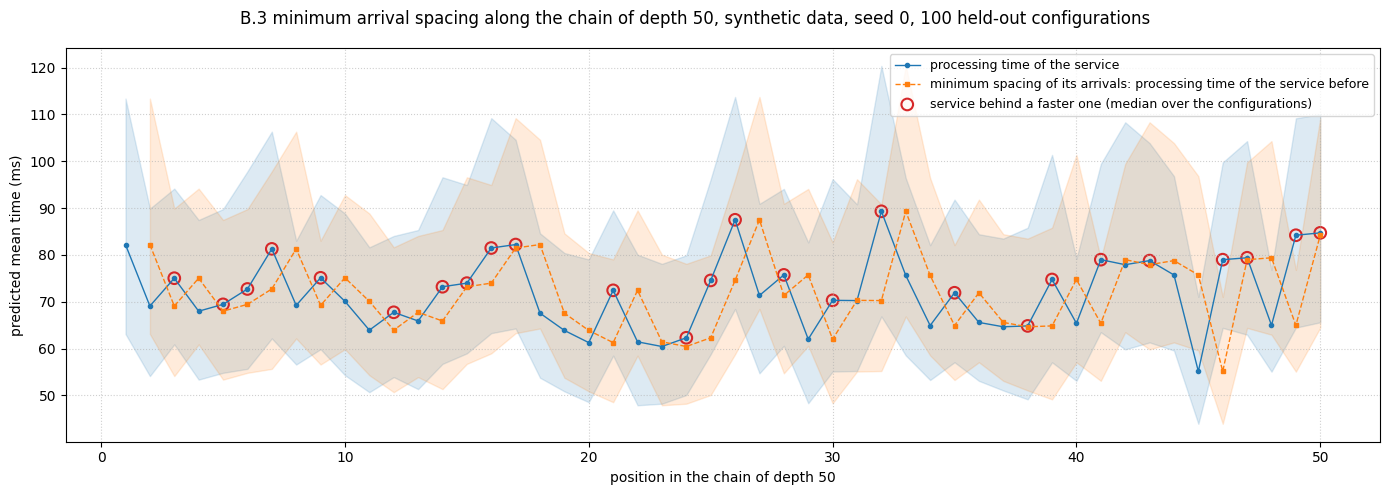

In [12]:
# The deepest chain: processing time of every service and minimum spacing of its arrivals, as the models predict them
processing = np.array([deepest_models["gp"][s].predict(deepest_x_test) for s in deepest_path]) * 1e3   # (positions, configurations), ms
spacing = processing[:-1]                                    # minimum spacing of the arrivals at the positions 2, 3, ...: processing time of the service before
behind_faster = np.mean(spacing < processing[1:], axis=1)    # share of the held-out configurations, per position
pessimistic_mean = np.array([mean for mean, _ in deepest_models["beliefs"]])
no_spacing_used = np.mean(np.array(deepest_models["lower_means"])[:-1] <= pessimistic_mean[1:], axis=1)   # Pegasus needs a clear margin between the two
positions = np.arange(1, len(deepest_path) + 1)
quartiles = lambda values: np.quantile(values, [0.25, 0.5, 0.75], axis=1)

fig, ax_spacing = plt.subplots(figsize=(14, 5))
for values, where, color, style, label in ((processing, positions, "tab:blue", "o-", "processing time of the service"),
                                           (spacing, positions[1:], "tab:orange", "s--", "minimum spacing of its arrivals: processing time of the service before")):
    low, middle, high = quartiles(values)
    ax_spacing.plot(where, middle, style, color=color, markersize=3, linewidth=1, label=label)
    ax_spacing.fill_between(where, low, high, color=color, alpha=0.15)
faster_before = quartiles(spacing)[1] < quartiles(processing[1:])[1]
ax_spacing.scatter(positions[1:][faster_before], quartiles(processing[1:])[1][faster_before], s=70, facecolors="none", edgecolors="tab:red", linewidths=1.5,
                   label="service behind a faster one (median over the configurations)")
ax_spacing.set_ylabel("predicted mean time (ms)")
ax_spacing.set_xlabel(f"position in the chain of depth {len(deepest_path)}")
ax_spacing.legend(loc="upper right", fontsize=9)
ax_spacing.grid(True, linestyle=":", alpha=0.6)
fig.suptitle(f"B.3 minimum arrival spacing along the chain of depth {len(deepest_path)}, {data_source} data, seed {seeds[0]}, {len(deepest_x_test)} held-out configurations")
plt.tight_layout()
plt.show()

In [13]:
display(Markdown(
    f"**What this shows** ({data_source} data, the chain of depth {len(deepest_path)} under seed {seeds[0]}, {workload['process']} arrivals at "
    f"{workload['rate']:g} items/s; shares over all later positions and held-out configurations).\n"
    f"- The service before is faster in {np.mean(behind_faster):.0%} of the cases. There the minimum spacing lies below the processing time of the "
    f"service, so the service can queue even though the service before releases one item at a time.\n"
    f"- Pegasus per node cannot use the minimum spacing in {np.mean(no_spacing_used):.0%} of the cases and bounds the service with the external "
    f"arrivals there, like the first service of the chain. In the remaining {1 - np.mean(no_spacing_used):.0%} its node bound also uses the minimum spacing."
))

**What this shows** (synthetic data, the chain of depth 50 under seed 0, poisson arrivals at 4 items/s; shares over all later positions and held-out configurations).
- The service before is faster in 51% of the cases. There the minimum spacing lies below the processing time of the service, so the service can queue even though the service before releases one item at a time.
- Pegasus per node cannot use the minimum spacing in 74% of the cases and bounds the service with the external arrivals there, like the first service of the chain. In the remaining 26% its node bound also uses the minimum spacing.

### B.4 Varying Load and Arrival Pattern

- **Synthetic:** partly. Renewal arrivals with any squared coefficient of variation $C^2$ of the gaps between arrivals
  (gamma-distributed gaps, run here), and any arrival rate (not swept here). Batching and diurnal arrivals are not
  implemented.
- **Real:** partly. Every experiment sweeps the arrival rate and adds bursts (factor 1, 2, 4, 8 for 1 or 2 s). Bursty
  and diurnal traces exist for qr → cv → face only (08a, incomplete). All arrivals are Poisson; there are no periodic
  ones. The column `offered_rate_cv` gives the variability of the offered rate for the $C^2$ axis.
- **Baselines:** as in B.1 without DNN Sum. Quantile Union and Conformal need every service monitored at every load and
  arrival pattern; the execution-time baseline and the proposed method do not.

**Setting.** For every seed, the chain, the training configurations, the per-service models and the held-out
configurations of B.1. Only the arrival process changes. A *gap* is the time between two consecutive arrivals at the
first service, in seconds. The gaps are independent and gamma-distributed with the mean of B.1 (1 ÷ arrival rate) and
the squared coefficient of variation $C^2$ = variance of a gap ÷ (mean of a gap)², one value of `arrival_cv2s` per
setting. $C^2 = 1$ gives the exponential gaps of a Poisson process, as in B.1. Below 1 the arrivals are spaced more
evenly; above 1 they come in bursts with long pauses between them. The arrival rate, and with it the utilization of
every service, is the same in every setting, so only the variability of the arrivals changes. The ground truth is
simulated anew for every $C^2$.

What each method knows about the arrivals: both versions of Pegasus use the moment generating function of a gap and
Kingman the value of $C^2$; both are given. Quantile Union and Conformal are trained anew for every $C^2$ on each
service monitored alone under that arrival process. GP Sum ignores the arrivals, so its latency is the same in every
setting.

**Figure.** The horizontal axis is $C^2$ (logarithmic), the vertical axis the tightness, for every seed the median over
its held-out configurations (logarithmic). The horizontal line at 1× is the measured quantile. Every line is the median
over the seeds, and the band around it reaches from the smallest to the largest seed. A filled marker means that the
method holds at that $C^2$ (it reaches the confidence level under every seed, as defined in B.1), a hollow marker that
it does not. Look at the markers first, then at how the filled lines move from left to right.

In [14]:
# B.4: the chains of B.1 under arrivals of different variability
arrival_cv2s = [0.25, 0.5, 1, 2, 4, 8]   # squared coefficient of variation of the gaps between arrivals; 1 is the Poisson process of B.1
arrival_methods, arrival_truth = {}, {}   # (cv2, seed) -> name -> (group, latency per held-out configuration) / (measured quantile, its lower edge)
for cv2 in arrival_cv2s:
    for s in seeds:
        data = load_chain_data(data_source, path=base.path, level=1 - alpha, coverage_check=coverage_check, seed=[seed, s], service_seed=s,
                               arrival_process="gamma", arrival_rate=workload["rate"], arrival_cv2=cv2)
        assert np.array_equal(data.x_test, bases[s].x_test), "the held-out configurations differ from those of B.1"
        # the execution times do not depend on the arrivals, so the per-service models of B.1 are the models of every setting
        assert all(np.array_equal(data.y_train[name], bases[s].y_train[name]) for name in data.path), "the training data differs from that of B.1"
        arrival_methods[(cv2, s)], _ = compare_methods(data, base_models[s], data.x_train, data.monitored_latencies, alpha, confidence, n_calibration,
                                                       model_seed=seed + s, leave_out=only_base_case)
        arrival_truth[(cv2, s)] = (data.measured, data.measured_low)
print(f"{len(arrival_methods)} combinations of arrival variability and seed evaluated.")

18 combinations of arrival variability and seed evaluated.


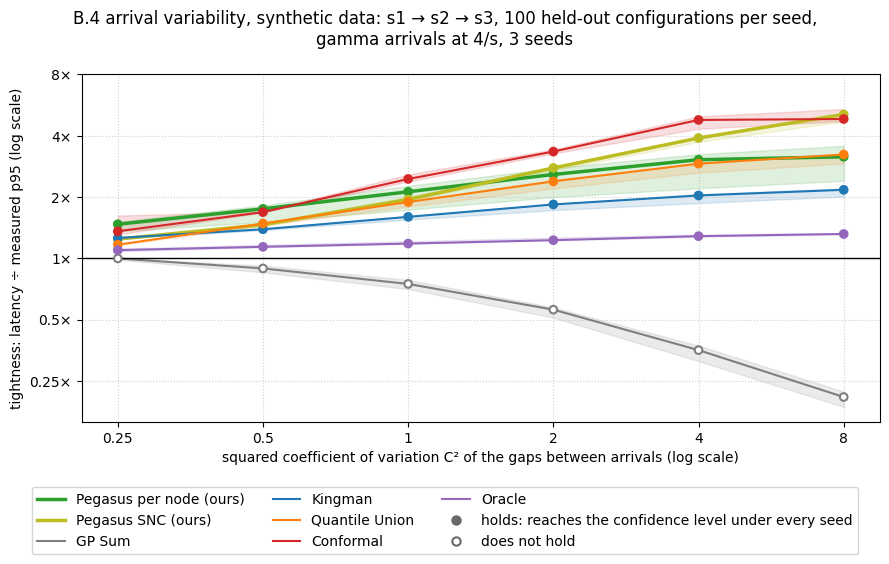

In [15]:
arrival_statistics = sweep_statistics(arrival_methods, arrival_truth, arrival_cv2s, seeds, confidence)   # name -> coverage, tightness, holds
tightness_sweep_figure(arrival_cv2s, arrival_statistics, "squared coefficient of variation C² of the gaps between arrivals (log scale)",
                       f"B.4 arrival variability, {data_source} data: {' → '.join(base.path)}, {len(base.x_test)} held-out configurations per seed,\n"
                       f"gamma arrivals at {workload['rate']:g}/s, {len(seeds)} seeds", p_label)

In [16]:
measured_at = lambda truth, value: np.median([np.median(truth[(value, s)][0]) for s in seeds])   # measured quantile (s): median over configurations, then seeds
display(Markdown(
    f"**What this shows** ({data_source} data, gamma arrivals at {workload['rate']:g} items/s, ε = {alpha:g}, {len(seeds)} seeds).\n"
    + sweep_conclusion(arrival_cv2s, arrival_statistics, sweep_competitors, lambda cv2: f"C² = {cv2:g}")
    + f"\n- **Ground truth.** The measured {p_label} of the end-to-end latency, the median over the held-out configurations, goes from "
    f"{measured_at(arrival_truth, arrival_cv2s[0]):.2f} s at C² = {arrival_cv2s[0]:g} to {measured_at(arrival_truth, arrival_cv2s[-1]):.2f} s at "
    f"C² = {arrival_cv2s[-1]:g}, at the same arrival rate. The Oracle, the union bound over measured services, is at "
    f"{np.nanmedian(arrival_statistics['Oracle']['tightness'][0]):.2f}× and {np.nanmedian(arrival_statistics['Oracle']['tightness'][-1]):.2f}×."
))

**What this shows** (synthetic data, gamma arrivals at 4 items/s, ε = 0.05, 3 seeds).
- **Validity.** Methods that hold in every setting, i.e. reach the confidence level under every seed: Pegasus per node (ours), Pegasus SNC (ours), Kingman, Quantile Union, Conformal. Methods that do not hold, and where: GP Sum at every setting.
- **Tightness among the methods that hold** (median over the seeds): Pegasus per node (ours) from 1.47× at C² = 0.25 to 3.15× at C² = 8; Pegasus SNC (ours) from 1.24× at C² = 0.25 to 5.08× at C² = 8; Kingman from 1.26× at C² = 0.25 to 2.17× at C² = 8; Quantile Union from 1.17× at C² = 0.25 to 3.23× at C² = 8; Conformal from 1.36× at C² = 0.25 to 4.83× at C² = 8.
- **Ground truth.** The measured p95 of the end-to-end latency, the median over the held-out configurations, goes from 0.23 s at C² = 0.25 to 1.10 s at C² = 8, at the same arrival rate. The Oracle, the union bound over measured services, is at 1.10× and 1.32×.

### B.5 Varying Tail Behaviors

- **Synthetic:** yes. The execution time of an item gets a lognormal factor whose shape sets how heavy the right tail
  is (`execution_times` in `pegasus/simulation.py`).
- **Real:** partly. p50, p95 and p99 of the processing time per run for every service; per-item values only from the
  `trace_steps.csv` of pipelines.
- **Baselines:** as in B.1 without DNN Sum. Quantile Union and Conformal assume no distribution; the execution-time
  baseline shares the Gaussian assumption.

**Setting.** For every seed, the chain, the training configurations, the held-out configurations and the Poisson
arrivals of B.1. Only the distribution of the execution time changes. The execution time of an item is its mean
execution time (the same function of the configuration as in B.1) multiplied by a factor $e^{\sigma z - \sigma^2/2}$,
where $z$ is the standard normal draw of the item and $\sigma$ the *tail shape*, one value of `execution_tails` per
setting; the Gaussian noise of B.1 is added as before. The factor is lognormal with mean 1, so the mean execution time
and the utilization of every service are the same in every setting. $\sigma = 0$ is the Gaussian execution time of
B.1. With a larger $\sigma$ most items are faster than the mean and a few are several times slower: the squared
coefficient of variation of the factor, variance ÷ mean², is $e^{\sigma^2} - 1$ and is printed under every tick of the
figure. The tail and the variance of the execution time therefore grow together.

Every model is trained anew for every $\sigma$, on data with that tail: one execution time per service and training
configuration for both versions of Pegasus, GP Sum and Kingman, and each service monitored alone for Quantile Union and
Conformal. No method is told the distribution. Both versions of Pegasus, GP Sum and Kingman treat an execution time as
Gaussian with the mean and the variance that the model of the service learned; Quantile Union and Conformal learn
latency quantiles and assume no distribution.

**Figure.** The horizontal axis is the tail shape $\sigma$, the vertical axis the tightness, for every seed the median
over its held-out configurations (logarithmic). The horizontal line at 1× is the measured quantile. Every line is the
median over the seeds, and the band around it reaches from the smallest to the largest seed. A filled marker means that
the method holds at that $\sigma$ (it reaches the confidence level under every seed, as defined in B.1), a hollow marker
that it does not. A seed under which a method gives no finite latency at half of the held-out configurations or more
counts as infinitely loose, and the method has no point where that is the case for half of the seeds or more; such a
bound is not violated, but it says nothing.

In [17]:
# B.5: the chains of B.1 with execution times of different tail shape
execution_tails = [0, 0.25, 0.5, 0.75, 1.0]   # shape sigma of the lognormal factor of the execution time; 0 is the Gaussian execution time of B.1
tail_methods, tail_truth = {}, {}             # (tail, seed) -> name -> (group, latency per held-out configuration) / (measured quantile, its lower edge)
with warnings.catch_warnings():
    # with heavy-tailed training data the fitted GP hyperparameters often end at their bounds, and scikit-learn warns for every such model
    warnings.simplefilter("ignore", ConvergenceWarning)
    for tail in execution_tails:
        for s in seeds:
            data = load_chain_data(data_source, path=base.path, level=1 - alpha, coverage_check=coverage_check, seed=[seed, s], service_seed=s,
                                   execution_tail=tail)
            assert np.array_equal(data.x_test, bases[s].x_test), "the held-out configurations differ from those of B.1"
            assert not (data.x_test[:, None, :] == data.x_train[None, :, :]).all(axis=2).any(), "a held-out configuration occurs in the training data"
            models = fit_services(data, data.x_train, data.y_train, model_seed=seed + s, confidence=confidence, with_dnn=False)
            tail_methods[(tail, s)], _ = compare_methods(data, models, data.x_train, data.monitored_latencies, alpha, confidence, n_calibration,
                                                         model_seed=seed + s, leave_out=only_base_case)
            tail_truth[(tail, s)] = (data.measured, data.measured_low)
print(f"{len(tail_methods)} combinations of tail shape and seed evaluated.")

15 combinations of tail shape and seed evaluated.


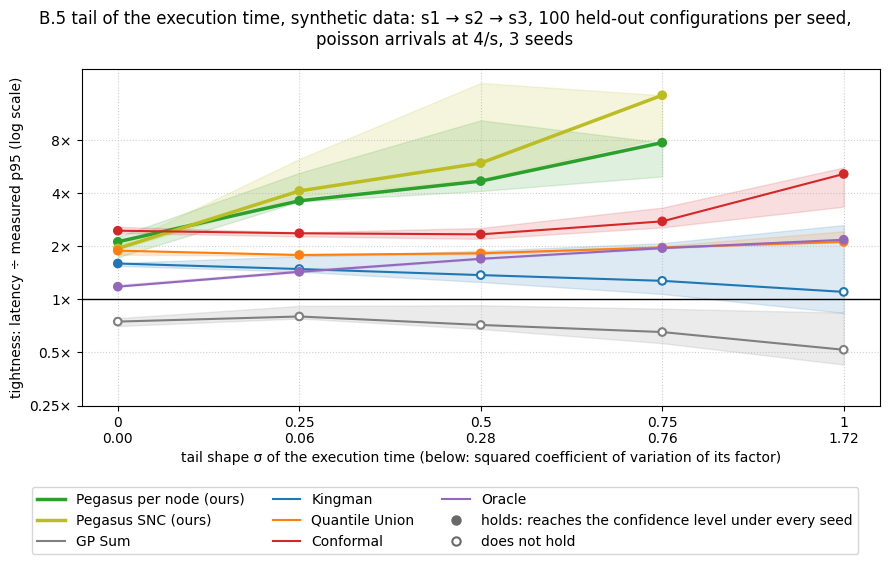

In [18]:
tail_statistics = sweep_statistics(tail_methods, tail_truth, execution_tails, seeds, confidence)   # name -> coverage, tightness, holds
factor_cv2 = lambda tail: np.expm1(tail ** 2)   # squared coefficient of variation of the lognormal factor with shape `tail`
tightness_sweep_figure(execution_tails, tail_statistics, "tail shape σ of the execution time (below: squared coefficient of variation of its factor)",
                       f"B.5 tail of the execution time, {data_source} data: {' → '.join(base.path)}, {len(base.x_test)} held-out configurations per seed,\n"
                       f"{workload['process']} arrivals at {workload['rate']:g}/s, {len(seeds)} seeds", p_label,
                       tick_labels=[f"{tail:g}\n{factor_cv2(tail):.2f}" for tail in execution_tails], log_x=False)

In [19]:
finite_share = lambda name, tail: np.median([np.mean(np.isfinite(tail_methods[(tail, s)][name][1])) for s in seeds])   # of the held-out configurations, median over the seeds
display(Markdown(
    f"**What this shows** ({data_source} data, {workload['process']} arrivals at {workload['rate']:g} items/s, ε = {alpha:g}, {len(seeds)} seeds).\n"
    + sweep_conclusion(execution_tails, tail_statistics, sweep_competitors, lambda tail: f"σ = {tail:g}")
    + f"\n- **Finite bounds.** Share of the held-out configurations at which a version of Pegasus gives a finite latency (median over the seeds): "
    + "; ".join(f"{name} " + ", ".join(f"{finite_share(name, tail):.0%} at σ = {tail:g}" for tail in execution_tails) for name in pegasus_versions)
    + ". Where a version gives none, the pessimistic mean execution time of a service is so large that the service counts as overloaded; such a bound "
    f"is not violated, but it says nothing.\n"
    f"- **Ground truth.** The measured {p_label} of the end-to-end latency, the median over the held-out configurations, goes from "
    f"{measured_at(tail_truth, execution_tails[0]):.2f} s at σ = {execution_tails[0]:g} to {measured_at(tail_truth, execution_tails[-1]):.2f} s at "
    f"σ = {execution_tails[-1]:g}, at the same mean execution times. The Oracle, the union bound over measured services, is at "
    f"{np.nanmedian(tail_statistics['Oracle']['tightness'][0]):.2f}× and {np.nanmedian(tail_statistics['Oracle']['tightness'][-1]):.2f}×."
))

**What this shows** (synthetic data, poisson arrivals at 4 items/s, ε = 0.05, 3 seeds).
- **Validity.** Methods that hold in every setting, i.e. reach the confidence level under every seed: Pegasus per node (ours), Pegasus SNC (ours), Quantile Union, Conformal. Methods that do not hold, and where: GP Sum at every setting; Kingman at σ = 0.25, σ = 0.5, σ = 0.75, σ = 1.
- **Tightness among the methods that hold** (median over the seeds): Pegasus per node (ours) from 2.12× at σ = 0 to 7.74× at σ = 0.75, and no finite bound for most seeds at σ = 1; Pegasus SNC (ours) from 1.94× at σ = 0 to 14.36× at σ = 0.75, and no finite bound for most seeds at σ = 1; Quantile Union from 1.89× at σ = 0 to 2.12× at σ = 1; Conformal from 2.45× at σ = 0 to 5.14× at σ = 1.
- **Finite bounds.** Share of the held-out configurations at which a version of Pegasus gives a finite latency (median over the seeds): Pegasus per node (ours) 100% at σ = 0, 100% at σ = 0.25, 100% at σ = 0.5, 100% at σ = 0.75, 0% at σ = 1; Pegasus SNC (ours) 100% at σ = 0, 100% at σ = 0.25, 100% at σ = 0.5, 100% at σ = 0.75, 0% at σ = 1. Where a version gives none, the pessimistic mean execution time of a service is so large that the service counts as overloaded; such a bound is not violated, but it says nothing.
- **Ground truth.** The measured p95 of the end-to-end latency, the median over the held-out configurations, goes from 0.31 s at σ = 0 to 0.91 s at σ = 1, at the same mean execution times. The Oracle, the union bound over measured services, is at 1.18× and 2.18×.

### B.6 Varying Percentiles

- **Synthetic:** yes, for every percentile that the simulated runs are long enough to measure.
- **Real:** partly. The campaign stores p50, p95 and p99 of the end-to-end time per run of a pipeline; other percentiles
  only from the per-request `traces.csv`, where they are intact.
- **Baselines:** as in B.1 without DNN Sum. Quantile Union and Conformal train one model per percentile; the other
  methods use the same execution-time models at every percentile.

**Setting.** For every seed, the chain, the training configurations, the per-service models, the held-out
configurations, the Poisson arrivals and the simulated runs of B.1. Only the percentile that a method has to bound
changes: the *level* is the share of items whose end-to-end latency must lie under the bound, one value of
`percentile_levels` per setting, written as a percentile (level 0.95 is p95, the percentile of B.1). The violation
probability is $\varepsilon$ = 1 − level, so a higher percentile is a smaller $\varepsilon$. The ground truth is the
measured quantile of the end-to-end latency at that level, with the confidence interval of B.1. The highest level is
limited by the length of the simulated runs: a quantile further in the tail would rest on too few items per run to be
measured, in particular the quantile at $1 - \varepsilon / K$ that Quantile Union, Conformal and the Oracle read from
the runs of each service.

How the level enters each method: Pegasus per node bounds every service at $\varepsilon / K$ and Pegasus SNC the whole
chain at $\varepsilon$, both with the same execution-time models as in B.1. GP Sum takes the level as the quantile of
its Gaussian sum, and Kingman as the quantile of its waiting-time formula. Quantile Union and Conformal are trained
anew for every level, on the $(1 - \varepsilon / K)$ latency quantile of each service monitored alone.

**Figure.** The horizontal axis is the bounded percentile, at equal distances from the lowest to the highest; the
vertical axis is the tightness, the latency of a method ÷ the measured quantile at that percentile, for every seed the
median over its held-out configurations (logarithmic). The horizontal line at 1× is the measured quantile. Every line
is the median over the seeds, and the band around it reaches from the smallest to the largest seed. A filled marker
means that the method holds at that percentile (it reaches the confidence level under every seed, as defined in B.1), a
hollow marker that it does not. Look at the markers first, then at whether a filled line comes closer to 1× or moves
away from it toward the higher percentiles.

In [20]:
# B.6: the chains of B.1 with a different percentile of the end-to-end latency to bound
percentile_levels = [0.5, 0.75, 0.9, 0.95, 0.99]   # level of the bounded latency quantile; the violation probability is 1 - level, and B.1 uses 1 - alpha
percentile_methods, percentile_truth = {}, {}       # (level, seed) -> name -> (group, latency per held-out configuration) / (measured quantile, its lower edge)
for level in percentile_levels:
    for s in seeds:
        data = load_chain_data(data_source, path=base.path, level=level, coverage_check=coverage_check, seed=[seed, s], service_seed=s)
        assert np.array_equal(data.x_test, bases[s].x_test), "the held-out configurations differ from those of B.1"
        # the execution times do not depend on the percentile, so the per-service models of B.1 are the models of every setting
        assert all(np.array_equal(data.y_train[name], bases[s].y_train[name]) for name in data.path), "the training data differs from that of B.1"
        percentile_methods[(level, s)], _ = compare_methods(data, base_models[s], data.x_train, data.monitored_latencies, 1 - level, confidence, n_calibration,
                                                            model_seed=seed + s, leave_out=only_base_case)
        percentile_truth[(level, s)] = (data.measured, data.measured_low)
print(f"{len(percentile_methods)} combinations of percentile and seed evaluated.")

15 combinations of percentile and seed evaluated.


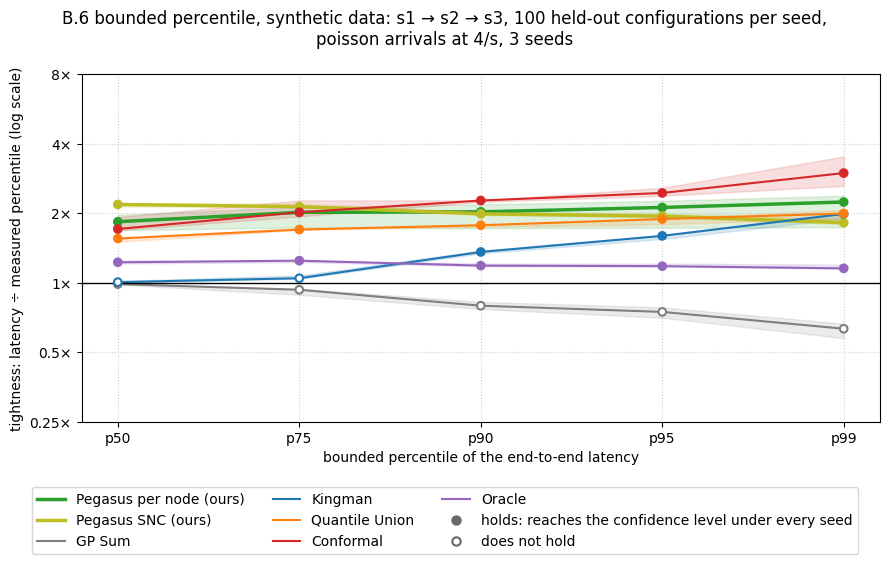

In [21]:
percentile_statistics = sweep_statistics(percentile_methods, percentile_truth, percentile_levels, seeds, confidence)   # name -> coverage, tightness, holds
percentile_label = lambda level: f"p{100 * level:g}"
# the percentiles are placed at equal distances, because neither the level nor the violation probability spreads them evenly
tightness_sweep_figure(list(range(len(percentile_levels))), percentile_statistics, "bounded percentile of the end-to-end latency",
                       f"B.6 bounded percentile, {data_source} data: {' → '.join(base.path)}, {len(base.x_test)} held-out configurations per seed,\n"
                       f"{workload['process']} arrivals at {workload['rate']:g}/s, {len(seeds)} seeds", "percentile",
                       tick_labels=[percentile_label(level) for level in percentile_levels], log_x=False)

In [22]:
display(Markdown(
    f"**What this shows** ({data_source} data, {workload['process']} arrivals at {workload['rate']:g} items/s, {len(seeds)} seeds).\n"
    + sweep_conclusion(percentile_levels, percentile_statistics, sweep_competitors, percentile_label)
    + f"\n- **Ground truth.** The measured percentile of the end-to-end latency, the median over the held-out configurations, goes from "
    f"{measured_at(percentile_truth, percentile_levels[0]):.2f} s at {percentile_label(percentile_levels[0])} to "
    f"{measured_at(percentile_truth, percentile_levels[-1]):.2f} s at {percentile_label(percentile_levels[-1])}. The Oracle, the union bound over "
    f"measured services, is at {np.nanmedian(percentile_statistics['Oracle']['tightness'][0]):.2f}× and "
    f"{np.nanmedian(percentile_statistics['Oracle']['tightness'][-1]):.2f}×."
))

**What this shows** (synthetic data, poisson arrivals at 4 items/s, 3 seeds).
- **Validity.** Methods that hold in every setting, i.e. reach the confidence level under every seed: Pegasus per node (ours), Pegasus SNC (ours), Quantile Union, Conformal. Methods that do not hold, and where: GP Sum at every setting; Kingman at p50, p75.
- **Tightness among the methods that hold** (median over the seeds): Pegasus per node (ours) from 1.84× at p50 to 2.24× at p99; Pegasus SNC (ours) from 2.18× at p50 to 1.82× at p99; Quantile Union from 1.56× at p50 to 2.00× at p99; Conformal from 1.71× at p50 to 2.99× at p99.
- **Ground truth.** The measured percentile of the end-to-end latency, the median over the held-out configurations, goes from 0.22 s at p50 to 0.37 s at p99. The Oracle, the union bound over measured services, is at 1.23× and 1.16×.

## C. Iterative Optimization of Service Bounds

**Note (speed of the bounds).** The experiments of this section compute the bound of Pegasus again and again: for every
candidate configuration or composition that an optimizer grades, and after every update with end-to-end samples. The
node bounds of Pegasus are closed formulas without a numerical resolution to trade against speed; B.3 reports their
computing time.

### C.1 Fine-Tuning Bounds with E2E Samples

- **Synthetic:** the data yes; no fine-tuning method is implemented.
- **Real:** the data yes (per-request `traces.csv` of the chains, where intact); the same method is missing.
- **Baselines:** the only experiment with models trained on runs of the chain, because using end-to-end
  samples is its subject: Fluxion-style and Deep GP Advanced with a growing number of samples. Reference: the proposed
  bound without fine-tuning.
- **Note:** Quantile Sum (one model per service that predicts its latency quantile, summed over the chain) is not a
  baseline of B.1; it is integrated here, trained as in Fluxion on the latencies observed in runs of the chain.

### C.2 Inferring Faster Service Compositions

- **Synthetic:** configuration optimization yes, with a new loop (choose by each model, simulate the chosen
  configuration). Composition search no: there are no interchangeable services and no genetic algorithm.
- **Real:** partly. A model can only rank the configurations that were measured for a chain, and the chains that were
  measured (04a–h, 06a–b); a chosen solution cannot be benchmarked anew.
- **Baselines:** as in B.1, each under the same optimizer.

## Real Data Outside the Paper's Structure

Trees (01, 03), a diamond (05a) and a fan-out (05b) are measured, but the methods handle chains only and the paper's
evaluation names no experiment for them.